# آزمایش حذف محافظه‌کارانه stopwordها برای BERT Mini

این نسخه بر مبنای **مدل ۲۵۶ توکنی، summary/head-tail، batch=128 و T4** ساخته شده است. تنها عامل آزمایشی جدید، حذف قانون‌مند stopwordهاست. معماری همان ۴ لایه، hidden size=256 و ۴ سر attention، آموزش کامل وزن‌ها، FP16، learning rate=`2e-5`، حداکثر ۴ epoch و انتخاب بهترین Validation Micro-F1 است.

**فرضیه قابل آزمایش:** با حذف تعداد محدودی واژه دستوری، بخشی از بودجه ۲۵۶ توکنی آزاد شود و اطلاعات بیشتری از review در ورودی جا بگیرد. این کار لزوماً دقت یا سرعت BERT را بهتر نمی‌کند؛ تصمیم را با Macro-F1، Micro-F1، MAE، نتایج هر کلاس و میزان کاهش واقعی توکن می‌گیریم. واژه پرتکرار الزاماً بی‌معنا نیست و این قواعد، تضمین حفظ کامل معنای همه جملات نیستند.

**روش سبک و قابل توضیح:** مدل یا وابستگی اضافه برای پاک‌سازی لازم نیست. فهرست ثابت ۱۵ واژه شامل `a, an, the, this, that, these, those, am, is, are, was, were, be, been, being` است. این‌ها نامزد حذف‌اند، نه واژه‌هایی که همیشه بی‌اثر باشند. قواعد نگه‌داری بر حذف اولویت دارند:

- منفی‌سازها، شدت‌دهنده‌ها، قیدهای مقدار/زمان، مقایسه‌ها، حروف ربط/اضافه، ضمیرهای شخصی و افعال وجهی حذف نمی‌شوند؛ سه واژه در دو طرف نشانه‌های حساس نیز محافظت می‌شود.
- contractionهایی مثل `isn't`, `don't`, `can't` یک واحد باقی می‌مانند. حذف در سطح کلمه کامل انجام می‌شود؛ حروف داخل کلمات یا قطعات WordPiece حذف نمی‌شوند.
- ترکیب‌های دارای خط تیره/اسلش، شناسه‌های مجاور نماد، واژه‌های تماماً بزرگ، متن داخل نقل‌قول و عبارت‌های مشخصی مانند `a lot`, `a bit`, `out of the box`, `human being` حفظ می‌شوند.
- عدد، واحد، emoji و نشانه‌گذاری، به‌ویژه `!` و `?`، حفظ می‌شوند. اگر حذف، تمام محتوای حرفی/عددی متن را از بین ببرد، همان متن اصلی استفاده می‌شود. شکل‌های بزرگ‌نویسی و واژه‌های باقی‌مانده بازنویسی نمی‌شوند.

**کنترل مقایسه:** ابتدا همان داده خام معتبر نصف و با نسبت ۷۰/۱۵/۱۵ تقسیم می‌شود. حذف stopword پس از split و پیش از انتخاب توکن‌ها اعمال می‌شود. تصمیم استفاده از summary از طول **review اصلی، پیش از حذف** گرفته می‌شود تا این تصمیم در دو اجرا یکسان بماند. برای review اصلی بلند، summary و review هر دو پاک‌سازی می‌شوند؛ اگر متن پاک‌شده در ۲۵۶ توکن جا شود، کامل وارد مدل می‌شود، وگرنه همان ۱۹۲ توکن اول و ۶۴ توکن آخر با احتساب `[CLS]/[SEP]` انتخاب می‌شود. review اصلی کوتاه، فقط از review پاک‌شده استفاده می‌کند.

در `BASELINE_RUN_DIR` مسیر اجرای **۲۵۶ توکنی قبلی بدون حذف stopword** را قرار دهید. همان splitها بازیابی و تنظیمات و summary اصلی تطبیق داده می‌شوند. با `REMOVE_STOPWORDS=False` می‌توان همین فایل را برای اجرای کنترل بدون حذف اجرا کرد. هر بار از runtime تازه یا همه سلول‌ها از ابتدا استفاده کنید.

Test در توسعه خاموش می‌ماند. فهرست و قواعد حذف قبل از دیدن نتایج ثابت‌اند و از label، validation یا test یاد گرفته نمی‌شوند. GPU T4 را در Colab انتخاب و سلول‌ها را به‌ترتیب اجرا کنید.


In [1]:
%pip install -q "transformers==4.57.1" "datasets>=3,<5" "accelerate>=1,<2" scikit-learn gdown pyarrow matplotlib


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## ۱. دریافت و خواندن داده
روش دریافت و خواندن فایل از نسخه اولیه حفظ شده است.


In [2]:
from pathlib import Path
import gdown

DATA_DIR = Path("/content/amazon_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

FILE_ID = "1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW"

# Preserve the original filename and extension.
downloaded_path = gdown.download(
    id=FILE_ID,
    output=str(DATA_DIR) + "/",
    quiet=False,
)

if downloaded_path is None:
    raise RuntimeError("Download failed. Check the file's sharing permissions.")

data_path = Path(downloaded_path)

print("Filename:", data_path.name)
print(f"File size: {data_path.stat().st_size / (1024**2):,.1f} MB")


Downloading...
From (original): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW
From (redirected): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW&confirm=t&uuid=7df8edf3-5182-4ac1-b69b-6950bffd65a3
To: /content/amazon_data/train_data.csv
100%|██████████| 635M/635M [00:09<00:00, 65.1MB/s]

Filename: train_data.csv
File size: 605.2 MB


In [3]:
import gzip
import json
import zipfile

import pandas as pd
from IPython.display import display

KEEP_COLUMNS = ["reviewText", "summary", "overall"]


def read_reviews(stream, filename):
    name = filename.lower()

    if name.endswith(".csv"):
        return pd.read_csv(
            stream,
            usecols=lambda column: column in KEEP_COLUMNS,
        )

    if name.endswith((".json", ".jsonl", ".ndjson")):
        # Inspect the first line to distinguish JSON Lines from a JSON array.
        first_line = stream.readline().strip()
        stream.seek(0)

        if first_line.startswith(b"["):
            frame = pd.read_json(stream)
            return frame.loc[:, frame.columns.intersection(KEEP_COLUMNS)]

        try:
            first_record = json.loads(first_line)
            is_json_lines = isinstance(first_record, dict)
        except json.JSONDecodeError:
            is_json_lines = False

        if is_json_lines:
            # Read in chunks to reduce temporary memory usage.
            chunks = pd.read_json(stream, lines=True, chunksize=50_000)
            frames = [
                chunk.loc[:, chunk.columns.intersection(KEEP_COLUMNS)]
                for chunk in chunks
            ]
            return pd.concat(frames, ignore_index=True)

        frame = pd.read_json(stream)
        return frame.loc[:, frame.columns.intersection(KEEP_COLUMNS)]

    raise ValueError(f"Unsupported file format: {filename}")


if zipfile.is_zipfile(data_path):
    with zipfile.ZipFile(data_path) as archive:
        candidates = [
            name for name in archive.namelist()
            if not name.startswith("__MACOSX/")
            and name.lower().endswith((".csv", ".json", ".jsonl", ".ndjson"))
        ]

        if len(candidates) != 1:
            raise ValueError(
                f"Expected one data file inside ZIP. Found: {candidates}"
            )

        with archive.open(candidates[0]) as stream:
            df = read_reviews(stream, candidates[0])

elif data_path.name.lower().endswith(".gz"):
    with gzip.open(data_path, "rb") as stream:
        df = read_reviews(stream, data_path.stem)

else:
    with data_path.open("rb") as stream:
        df = read_reviews(stream, data_path.name)

required_columns = {"reviewText", "overall"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print(f"Number of reviews: {len(df):,}")
print("Loaded columns:", df.columns.tolist())
display(df.head())


Number of reviews: 838,944
Loaded columns: ['overall', 'reviewText', 'summary']


,overall,reviewText,summary
0,2,I have an older URC-WR7 remote and thought thi...,Cannot Learn
1,5,First time I've EVER had a remote that needed ...,zero programming needed! Miracle!?
2,4,Got them and only 2 of them worked. company ca...,Works Good and programs easy.
3,5,I got tired of the remote being on the wrong s...,Same as TWC remote
4,5,After purchasing cheap cords from another webs...,Good Quality Cord


## ۲. تنظیمات ثابت آزمایش
برای مقایسه معماری‌ها، این تنظیمات و splitها را ثابت نگه دارید. هر اجرا پوشه مجزا دارد.


In [4]:
import os, json, hashlib, shutil, time, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import transformers, datasets, sklearn
from sklearn.model_selection import train_test_split
from transformers import set_seed
from google.colab import drive

SEED = 42
MODEL_NAME = "google/bert_uncased_L-4_H-256_A-4"
MAX_LENGTH = 256
HEAD_TOKENS = 192
TAIL_TOKENS = 64
TRAIN_BATCH_SIZE = 128
GRADIENT_ACCUMULATION_STEPS = 1
EVAL_BATCH_SIZE = 128
EPOCHS = 4
LEARNING_RATE = 2e-5
REMOVE_STOPWORDS = True
RUN_TEST = False  # Enable only after the model-development decisions are final.
# Example: '/content/drive/MyDrive/amazon_sentiment/experiments_256/PREVIOUS_256_RUN_ID'
BASELINE_RUN_DIR = None  # Previous 256-token run WITHOUT stopword removal; reuse splits and compare.
REUSE_SPLITS_DIR = None  # Alternatively, set the previous run's 'splits' directory.
if BASELINE_RUN_DIR is not None and REUSE_SPLITS_DIR is None:
    REUSE_SPLITS_DIR = str(Path(BASELINE_RUN_DIR)/'splits')

set_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("Select Runtime > Change runtime type > GPU in Colab.")
drive.mount('/content/drive')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
LOCAL_RUN_DIR = Path('/content/amazon_stopword_runs') / RUN_ID
RUN_DIR = Path('/content/drive/MyDrive/amazon_sentiment/experiments_stopwords') / RUN_ID
SPLITS_DIR = RUN_DIR / 'splits'
CHECKPOINT_DIR = LOCAL_RUN_DIR / 'checkpoints'
for directory in [LOCAL_RUN_DIR, RUN_DIR, SPLITS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print('GPU:', torch.cuda.get_device_name(0))
print('Results:', RUN_DIR)

print('Physical training batch:', TRAIN_BATCH_SIZE)
print('Effective training batch:', TRAIN_BATCH_SIZE*GRADIENT_ACCUMULATION_STEPS)
if 'T4' not in torch.cuda.get_device_name(0):
    print('This run was configured for T4; the detected GPU is recorded in the results.')

# Record the intended control before training, and reject a mismatched experiment.
baseline_config = None
if BASELINE_RUN_DIR is not None:
    base_dir = Path(BASELINE_RUN_DIR)
    baseline_config = json.loads((base_dir/'experiment_config.json').read_text())
    expected = {'model':MODEL_NAME, 'max_length':MAX_LENGTH,
                'train_batch':TRAIN_BATCH_SIZE, 'eval_batch':EVAL_BATCH_SIZE,
                'gradient_accumulation_steps':GRADIENT_ACCUMULATION_STEPS,
                'epochs_max':EPOCHS, 'seed':SEED,
                'selection_metric':'micro_f1', 'early_stopping_patience':2}
    for key, value in expected.items():
        if baseline_config.get(key) != value:
            raise ValueError(f'Baseline differs in {key}: {baseline_config.get(key)} != {value}')
    if baseline_config.get('remove_stopwords',False):
        raise ValueError('The control run must have stopword removal disabled.')
    old_args = baseline_config['training_args']
    for key,value in {'learning_rate':LEARNING_RATE,'weight_decay':0.01,
                      'warmup_ratio':0.06,'lr_scheduler_type':'linear',
                      'fp16':True,'bf16':False,'optim':'adamw_torch'}.items():
        if old_args.get(key)!=value:
            raise ValueError(f'Training configuration differs in {key}.')


Mounted at /content/drive
GPU: Tesla T4
Results: /content/drive/MyDrive/amazon_sentiment/experiments_stopwords/20261105_142515_903389
Physical training batch: 128
Effective training batch: 128


## ۳. پاک‌سازی، انتخاب نصف داده و تقسیم stratified
شناسه ردیف اصلی پیش از reset index نگه داشته می‌شود. این تقسیم در سطح ردیف است؛ برای تعمیم به کاربران یا محصولات جدید به آزمایشی با تقسیم گروهی نیاز است. متن‌های تکراری احتمالی حذف نمی‌شوند تا پروتکل پاک‌سازی اولیه حفظ شود؛ میزان هم‌پوشانی متن‌ها گزارش می‌شود.


In [5]:
if 'summary' not in df.columns:
    raise ValueError("The input file must include 'summary' for this experiment.")
# Keep the BASELINE fingerprint independent of the newly added input feature.
summary_by_id = df['summary'].fillna('').astype(str).str.strip().reset_index(drop=True)
data = df[['reviewText', 'overall']].copy()
data['source_row_id'] = np.arange(len(data), dtype=np.int64)
data['overall'] = pd.to_numeric(data['overall'], errors='coerce')
data['reviewText'] = data['reviewText'].astype('string').str.strip()
valid = (data['overall'].isin([1,2,3,4,5]) & data['reviewText'].notna()
         & data['reviewText'].ne('')).fillna(False)
data = data.loc[valid].copy()
data['overall'] = data['overall'].astype('int64')
data['labels'] = data['overall'] - 1
data = data.reset_index(drop=True)
# Include cleaned text, labels and row identity in the data fingerprint.
fingerprint = hashlib.sha256(
    pd.util.hash_pandas_object(data, index=False).values.tobytes()
).hexdigest()

if REUSE_SPLITS_DIR is None:
    selected_df, _ = train_test_split(
        data, train_size=0.5, stratify=data['labels'], random_state=SEED)
    train_df, remaining = train_test_split(
        selected_df, test_size=0.30,
        stratify=selected_df['labels'], random_state=SEED)
    val_df, test_df = train_test_split(
        remaining, test_size=0.50, stratify=remaining['labels'], random_state=SEED)
else:
    old_dir = Path(REUSE_SPLITS_DIR)
    previous = json.loads((old_dir/'split_manifest.json').read_text())
    assert previous['data_fingerprint'] == fingerprint, 'Input data changed.'
    assert previous['seed'] == SEED, 'Split seed changed.'
    train_df, val_df, test_df = [pd.read_parquet(old_dir/f'{s}.parquet')
                                for s in ['train','validation','test']]
    # Verify saved rows against current input before attaching summaries.
    current = data.set_index('source_row_id')
    for frame in [train_df, val_df, test_df]:
        saved_ids = frame['source_row_id'].to_numpy()
        expected = current.loc[saved_ids]
        assert np.array_equal(expected['labels'].to_numpy(), frame['labels'].to_numpy())
        assert np.array_equal(expected['reviewText'].to_numpy(), frame['reviewText'].to_numpy())
    selected_df = pd.concat([train_df,val_df,test_df], ignore_index=True)

# Copies avoid chained assignment and preserve the stored row order.
train_df, val_df, test_df = [f.copy() for f in [train_df, val_df, test_df]]
for frame in [train_df, val_df, test_df]:
    frame['summary'] = summary_by_id.iloc[frame['source_row_id'].to_numpy()].to_numpy()
split_frames = {'train': train_df, 'validation': val_df, 'test': test_df}
id_sets = [set(f['source_row_id']) for f in split_frames.values()]
assert all(len(ids)==len(frame) for ids,frame in zip(id_sets,split_frames.values()))
assert all(id_sets[i].isdisjoint(id_sets[j]) for i,j in [(0,1),(0,2),(1,2)])
assert sum(map(len,split_frames.values())) == len(data)//2
split_fingerprint = hashlib.sha256(b''.join(
    np.sort(f['source_row_id'].to_numpy(dtype=np.int64)).tobytes()
    for f in split_frames.values())).hexdigest()
for name, frame in split_frames.items():
    frame.reset_index(drop=True).to_parquet(SPLITS_DIR/f'{name}.parquet', index=False)
manifest = {'seed': SEED, 'data_fingerprint':fingerprint,
            'split_fingerprint':split_fingerprint, 'sampling_fraction':0.5,
            'ratios':[0.70,0.15,0.15],
            'sizes':{name:len(f) for name,f in split_frames.items()},
            'summary_fingerprint': hashlib.sha256(pd.util.hash_pandas_object(
                summary_by_id, index=False).values.tobytes()).hexdigest()}
(SPLITS_DIR/'split_manifest.json').write_text(json.dumps(manifest,indent=2))
def percentages(frame):
    return frame['overall'].value_counts(normalize=True).reindex(range(1,6),fill_value=0)*100
display(pd.DataFrame({'All usable (%)':percentages(data),
                      'Selected half (%)':percentages(selected_df),
                      **{name+' (%)':percentages(f) for name,f in split_frames.items()}}).round(3))
print('Usable:',len(data), '| Selected:',len(selected_df))
print('Sizes:', manifest['sizes'])
print('Reuse these splits:', SPLITS_DIR)
text_sets = {name:set(f['reviewText']) for name,f in split_frames.items()}
duplicate_overlap = {f'{a} vs {b}':len(text_sets[a]&text_sets[b])
    for a,b in [('train','validation'),('train','test'),('validation','test')]}
print('Number of distinct identical texts shared between splits:',duplicate_overlap)
(RUN_DIR/'duplicate_text_overlap.json').write_text(json.dumps(duplicate_overlap,indent=2))
del text_sets, df, data, selected_df, summary_by_id

if baseline_config is not None:
    assert baseline_config['split_fingerprint']==split_fingerprint, 'Different row splits.'
    assert baseline_config['summary_fingerprint']==manifest['summary_fingerprint'], \
        'Raw summaries changed between experiments.'


,All usable (%),Selected half (%),train (%),validation (%),test (%)
overall,,,,,
1,9.887,9.887,9.887,9.887,9.889
2,6.765,6.765,6.765,6.766,6.764
3,9.683,9.683,9.683,9.684,9.684
4,18.656,18.656,18.656,18.655,18.657
5,55.008,55.008,55.008,55.009,55.007


Usable: 838944 | Selected: 419472
Sizes: {'train': 293630, 'validation': 62921, 'test': 62921}
Reuse these splits: /content/drive/MyDrive/amazon_sentiment/experiments_stopwords/20261105_142515_903389/splits
Number of distinct identical texts shared between splits: {'train vs validation': 1732, 'train vs test': 1714, 'validation vs test': 386}


## ۴. پاک‌سازی محافظه‌کارانه و توکن‌سازی

در سلول اول، فهرست حذف، کلمات محافظت‌شده، عبارت‌های استثنا و مثال‌ها مشخص‌اند. سلول دوم همان Mini BERT و ورودی head-tail را آماده می‌کند. Dynamic padding تا بلندترین ورودی batch و مضرب ۸ است. هیچ stemming، lemmatization، حذف punctuation یا حذف عمومی حروف اجرا نمی‌شود.


In [6]:
import re
from collections import Counter

REMOVAL_CANDIDATES = frozenset('a an the this that these those am is are was were be been being'.split())
SENSITIVE_CUES = frozenset('no not never neither nor none nobody nothing nowhere without cannot\nvery really too so quite rather extremely highly barely hardly scarcely little less more most least\nenough only just even almost nearly somewhat pretty absolutely totally completely particularly\nespecially much many few always often sometimes usually seldom rarely lot bit couple\nbut however although though yet nevertheless nonetheless except unless until if when whereas while\ninstead versus vs compared than as better worse best worst\ncan could would should might may must will shall need ought\nnow then before after still already anymore ever since once again used recently previously currently'.split())
PROTECT_WINDOW = 3
PROTECTED_PHRASES = (
    'a lot','a bit','a little','a few','a couple','a great deal','a must',
    'as a whole','on the other hand','all the time','at the same time',
    'the very','the more','the less','the most','the least','so that','now that',
    'provided that','such that','in that','in the end','out of the box',
    'the other','that said','this said','human being','human beings','be able','being able',
)
PHRASES_BY_FIRST = {}
for _phrase in PROTECTED_PHRASES:
    _parts = tuple(_phrase.split())
    PHRASES_BY_FIRST.setdefault(_parts[0], []).append(_parts)
# Preserve apostrophes inside contractions and hyphenated/slash-separated tokens.
LEXEME_RE = re.compile(r"\w+(?:['’/\-]\w+)*", re.UNICODE)
QUOTE_RE = re.compile(r'''"[^"\n]*"|“[^”\n]*”|‘[^’\n]*’|(?<!\w)'[^'\n]+'(?!\w)''')

def lookup_form(word):
    return word.casefold().replace('’', "'")

def clean_stopwords(text, enabled=True):
    original = '' if text is None else str(text).strip()
    if not enabled or not original:
        return original, [], False
    matches = list(LEXEME_RE.finditer(original))
    forms = [lookup_form(m.group()) for m in matches]
    protected = set()
    for i,word in enumerate(forms):
        if word in SENSITIVE_CUES or word.endswith("n't"):
            protected.update(range(max(0,i-PROTECT_WINDOW),min(len(forms),i+PROTECT_WINDOW+1)))
    for i,word in enumerate(forms):
        for parts in PHRASES_BY_FIRST.get(word, ()):
            if tuple(forms[i:i+len(parts)]) == parts:
                protected.update(range(i,i+len(parts)))
    quote_spans = [m.span() for m in QUOTE_RE.finditer(original)]
    removed = []
    chunks = []
    cursor = 0
    for i,m in enumerate(matches):
        token = m.group()
        word = forms[i]
        if word not in REMOVAL_CANDIDATES or i in protected:
            continue
        if token.isupper() or any(a<=m.start() and m.end()<=b for a,b in quote_spans):
            continue
        left = original[m.start()-1] if m.start() else ''
        right = original[m.end()] if m.end()<len(original) else ''
        # Keep identifiers/labels such as A+, a@example, #the and a.com.
        if (left and left in '@#_/-+\\=') or (right and right in '@#_/-+\\='):
            continue
        if ((right=='.' and m.end()+1<len(original) and original[m.end()+1].isalnum())
                or (left=='.' and m.start()>1 and original[m.start()-2].isalnum())):
            continue
        chunks.append(original[cursor:m.start()])
        cursor=m.end()
        removed.append(word)
    if not removed:
        return original, [], False
    chunks.append(original[cursor:])
    cleaned = re.sub(r'[ \t]{2,}', ' ', ''.join(chunks)).strip()
    if not any(char.isalnum() for char in cleaned):
        return original, [], True
    return cleaned, removed, False

STOPWORD_POLICY = {
    'version':'conservative_lexical_v1',
    'removal_candidates':sorted(REMOVAL_CANDIDATES),
    'sensitive_cues':sorted(SENSITIVE_CUES),
    'protected_phrases':list(PROTECTED_PHRASES),
    'protect_window':PROTECT_WINDOW,
    'lexeme_regex':LEXEME_RE.pattern,'quote_regex':QUOTE_RE.pattern,
    'preserve_punctuation':True,'preserve_contractions':True,
    'preserve_uppercase_identifiers':True,'preserve_quoted_spans':True,
    'empty_after_deletion_fallback':'original_text',
}
stopword_policy_fingerprint = hashlib.sha256(
    json.dumps(STOPWORD_POLICY,sort_keys=True).encode()).hexdigest()
(RUN_DIR/'stopword_policy.json').write_text(json.dumps(STOPWORD_POLICY,indent=2))
demo_reviews = [
    'The product is good and the battery lasts.',
    'The sound is not very good, but the battery is excellent!',
    "It isn't bad at all; I can't complain.",
    'This is a bit better than the old one.',
    'The USB-C adapter is 5-in-1 and supports A/B testing.',
    'The product named "The Last of Us" is excellent.',
    'the is a',
]
display(pd.DataFrame([{'original':t, 'processed':clean_stopwords(t,REMOVE_STOPWORDS)[0],
                       'removed_words':clean_stopwords(t,REMOVE_STOPWORDS)[1]}
                      for t in demo_reviews]))


,original,processed,removed_words
0,The product is good and the battery lasts.,product good and battery lasts.,"[the, is, the]"
1,"The sound is not very good, but the battery is...","The sound is not very good, but the battery is...",[]
2,It isn't bad at all; I can't complain.,It isn't bad at all; I can't complain.,[]
3,This is a bit better than the old one.,This is a bit better than the old one.,[]
4,The USB-C adapter is 5-in-1 and supports A/B t...,USB-C adapter 5-in-1 and supports A/B testing.,"[the, is]"
5,"The product named ""The Last of Us"" is excellent.","product named ""The Last of Us"" excellent.","[the, is]"
6,the is a,the is a,[]


In [7]:
from datasets import Dataset, DatasetDict, Features, Sequence, Value
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
set_seed(SEED)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,num_labels=5,
    id2label={i:str(i+1) for i in range(5)},
    label2id={str(i+1):i for i in range(5)})
for parameter in model.parameters():
    parameter.requires_grad=True
assert (model.config.num_hidden_layers,model.config.hidden_size,model.config.num_attention_heads)==(4,256,4)
print('Parameters:',format(sum(p.numel() for p in model.parameters()),','))
SPECIAL_TOKENS = tokenizer.num_special_tokens_to_add(pair=False)
assert SPECIAL_TOKENS==2 and HEAD_TOKENS+TAIL_TOKENS==MAX_LENGTH
CONTENT_LIMIT = MAX_LENGTH-SPECIAL_TOKENS
HEAD_CONTENT,TAIL_CONTENT = HEAD_TOKENS-1,TAIL_TOKENS-1
MODEL_KEYS = ['input_ids','attention_mask','token_type_ids']
PREPROCESSING_CONFIG = {
    'max_length':MAX_LENGTH,'head_tokens_with_cls':HEAD_TOKENS,
    'tail_tokens_with_sep':TAIL_TOKENS,'short_input':'cleaned_reviewText_only',
    'long_input':'cleaned_summary + single_space + cleaned_reviewText',
    'summary_eligibility':'original_review_content_tokens > 254 BEFORE stopword removal',
    'remove_stopwords':REMOVE_STOPWORDS,
    'stopword_policy_fingerprint':stopword_policy_fingerprint,
    'dynamic_padding':True,'pad_to_multiple_of':8,
}

def select_content_ids(content_ids):
    if len(content_ids)<=CONTENT_LIMIT:
        return list(content_ids)
    return list(content_ids[:HEAD_CONTENT])+list(content_ids[-TAIL_CONTENT:])

def wrap_content_ids(content_ids):
    ids=tokenizer.build_inputs_with_special_tokens(content_ids)
    assert len(ids)<=MAX_LENGTH
    return {'input_ids':ids,'attention_mask':[1]*len(ids),
            'token_type_ids':tokenizer.create_token_type_ids_from_sequences(content_ids)}

def encode_texts(texts):
    return tokenizer(texts,add_special_tokens=False,truncation=False,
                     padding=False,verbose=False)['input_ids']

def prepare_batch(batch, enabled=None):
    if enabled is None:
        enabled=REMOVE_STOPWORDS
    reviews=[str(text).strip() for text in batch['reviewText']]
    summaries=['' if text is None else str(text).strip() for text in batch['summary']]
    raw_review_ids=encode_texts(reviews)
    # Freeze summary eligibility at the ORIGINAL review length for the ablation.
    is_long=[len(ids)>CONTENT_LIMIT for ids in raw_review_ids]
    cleaned=[clean_stopwords(text,enabled) for text in reviews]
    clean_reviews=[item[0] for item in cleaned]
    clean_review_ids=encode_texts(clean_reviews) if enabled else raw_review_ids
    raw_sources=list(raw_review_ids)
    clean_sources=list(clean_review_ids)
    cleaned_summaries=[('',[],False) for _ in reviews]
    combined_indices=[i for i,long in enumerate(is_long) if long and summaries[i]]
    if combined_indices:
        for i in combined_indices:
            cleaned_summaries[i]=clean_stopwords(summaries[i],enabled)
        raw_combined=[summaries[i]+' '+reviews[i] for i in combined_indices]
        clean_combined=[(cleaned_summaries[i][0]+' '+clean_reviews[i]).strip()
                        for i in combined_indices]
        raw_combined_ids=encode_texts(raw_combined)
        clean_combined_ids=encode_texts(clean_combined) if enabled else raw_combined_ids
        for i,raw_ids,clean_ids in zip(combined_indices,raw_combined_ids,clean_combined_ids):
            raw_sources[i]=raw_ids
            clean_sources[i]=clean_ids
    features={key:[] for key in MODEL_KEYS}
    audit={key:[] for key in [
        'raw_review_content_tokens','clean_review_content_tokens',
        'raw_source_content_tokens','clean_source_content_tokens',
        'raw_model_input_tokens','clean_model_input_tokens',
        'summary_eligible','raw_truncated','clean_truncated',
        'review_fallback','summary_fallback','removed_review_words','removed_summary_words']}
    for i,content in enumerate(clean_sources):
        example=wrap_content_ids(select_content_ids(content))
        for key in features:
            features[key].append(example[key])
        values={
            'raw_review_content_tokens':len(raw_review_ids[i]),
            'clean_review_content_tokens':len(clean_review_ids[i]),
            'raw_source_content_tokens':len(raw_sources[i]),
            'clean_source_content_tokens':len(content),
            'raw_model_input_tokens':min(len(raw_sources[i])+SPECIAL_TOKENS,MAX_LENGTH),
            'clean_model_input_tokens':len(example['input_ids']),
            'summary_eligible':is_long[i],
            'raw_truncated':len(raw_sources[i])>CONTENT_LIMIT,
            'clean_truncated':len(content)>CONTENT_LIMIT,
            'review_fallback':cleaned[i][2],
            'summary_fallback':cleaned_summaries[i][2],
            'removed_review_words':cleaned[i][1],
            'removed_summary_words':cleaned_summaries[i][1],
        }
        for key,value in values.items():
            audit[key].append(value)
    return features,audit

def tokenize_batch(batch):
    return prepare_batch(batch)[0]

def tokenize_with_audit(batch):
    features,audit=prepare_batch(batch)
    return {**features,**audit}

# Exercise boundaries with the actual BERT tokenizer before processing the data.
probe={'reviewText':['good product','good '*254,'good '*255,
                     'the product is '*100,'bad '*400],
       'summary':['ignored','ignored','excellent','unique summary marker','']}
features,audit=prepare_batch(probe,enabled=True)
assert [len(ids) for ids in features['input_ids'][:3]]==[4,256,256]
assert features['input_ids'][0]==tokenizer('good product')['input_ids']
assert audit['summary_eligible'][3] and audit['raw_review_content_tokens'][3]>254
assert audit['clean_review_content_tokens'][3]<=254
assert not audit['clean_truncated'][3]
assert features['input_ids'][3]==tokenizer('unique summary marker '+'product '*100)['input_ids']
control,_=prepare_batch(probe,enabled=False)
for i,review in enumerate(probe['reviewText']):
    raw_ids=encode_texts([review])[0]
    combined=(probe['summary'][i]+' '+review).strip() if len(raw_ids)>254 else review.strip()
    wrapped=tokenizer(combined)['input_ids']
    expected=wrapped if len(wrapped)<=256 else wrapped[:192]+wrapped[-64:]
    assert control['input_ids'][i]==expected
data_collator=DataCollatorWithPadding(tokenizer=tokenizer,pad_to_multiple_of=8)
padded=data_collator([{key:value[i] for key,value in features.items()} for i in range(5)])
assert padded['attention_mask'].sum(dim=1).tolist()==[len(ids) for ids in features['input_ids']]
assert padded['input_ids'].shape[1]==256
del padded
print('BERT tokenizer boundaries, frozen summary eligibility and padding checks passed.')

raw_datasets=DatasetDict({name:Dataset.from_pandas(
    frame[['reviewText','summary','labels']],preserve_index=False)
    for name,frame in [('train',train_df),('validation',val_df)]})
preprocessing_start=time.perf_counter()
# Explicit types also handle batches where every removed-word list is empty.
audit_features=Features({
    'labels':Value('int64'),
    **{key:Sequence(Value('int64')) for key in MODEL_KEYS},
    **{key:Value('int64') for key in [
        'raw_review_content_tokens','clean_review_content_tokens',
        'raw_source_content_tokens','clean_source_content_tokens',
        'raw_model_input_tokens','clean_model_input_tokens']},
    **{key:Value('bool') for key in ['summary_eligible','raw_truncated','clean_truncated',
                                    'review_fallback','summary_fallback']},
    'removed_review_words':Sequence(Value('string')),
    'removed_summary_words':Sequence(Value('string')),
})
tokenized_with_audit=raw_datasets.map(
    tokenize_with_audit,batched=True,batch_size=256,
    remove_columns=['reviewText','summary'],features=audit_features,
    desc='Stopword filtering and tokenization')
preprocessing_seconds=time.perf_counter()-preprocessing_start

# Save token statistics without passing audit fields into the model/collator.
preprocessing_report={}
frequency_rows=[]
for name in ['train','validation']:
    dataset=tokenized_with_audit[name]
    audit_columns=[key for key in dataset.column_names if key not in MODEL_KEYS+['labels']]
    audit_frame=dataset.select_columns(audit_columns).to_pandas()
    audit_frame.insert(0,'source_row_id',split_frames[name]['source_row_id'].to_numpy())
    audit_frame.to_parquet(RUN_DIR/f'{name}_token_audit.parquet',index=False)
    raw_total=int(audit_frame['raw_source_content_tokens'].sum())
    clean_total=int(audit_frame['clean_source_content_tokens'].sum())
    model_raw=int(audit_frame['raw_model_input_tokens'].sum())
    model_clean=int(audit_frame['clean_model_input_tokens'].sum())
    removed_counts=Counter(word for words in audit_frame['removed_review_words'] for word in words)
    removed_counts.update(word for words in audit_frame['removed_summary_words'] for word in words)
    preprocessing_report[name]={
        'rows':len(dataset),'raw_source_tokens_total':raw_total,
        'clean_source_tokens_total':clean_total,
        'source_token_reduction_pct':100*(raw_total-clean_total)/max(raw_total,1),
        'model_input_reduction_pct':100*(model_raw-model_clean)/max(model_raw,1),
        'mean_model_input_before':float(audit_frame['raw_model_input_tokens'].mean()),
        'mean_model_input_after':float(audit_frame['clean_model_input_tokens'].mean()),
        'truncated_before_pct':100*float(audit_frame['raw_truncated'].mean()),
        'truncated_after_pct':100*float(audit_frame['clean_truncated'].mean()),
        'newly_fit_rows':int((audit_frame['raw_truncated'] & ~audit_frame['clean_truncated']).sum()),
        'applied_word_removals':int(sum(removed_counts.values())),
        'review_fallback_rows':int(audit_frame['review_fallback'].sum()),
    }
    frequency_rows.extend({'split':name,'word':word,'count':count}
                          for word,count in removed_counts.most_common())
    del audit_frame
tokenized_datasets=DatasetDict({name:tokenized_with_audit[name].select_columns(MODEL_KEYS+['labels'])
                               for name in ['train','validation']})
del tokenized_with_audit
pd.DataFrame(frequency_rows,columns=['split','word','count']).to_csv(
    RUN_DIR/'removed_stopword_frequencies.csv',index=False)
(RUN_DIR/'preprocessing_report.json').write_text(json.dumps(preprocessing_report,indent=2))
display(pd.DataFrame(preprocessing_report).T)
print('Filtering/tokenization time (minutes):',round(preprocessing_seconds/60,2))
examples=[]
for row in train_df.head(30).itertuples():
    processed,removed,fallback=clean_stopwords(row.reviewText,REMOVE_STOPWORDS)
    examples.append({'source_row_id':row.source_row_id,'original':row.reviewText,
                     'processed':processed,'removed_words':' '.join(removed),'fallback':fallback})
pd.DataFrame(examples).to_csv(RUN_DIR/'stopword_examples_train.csv',index=False)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/383 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/45.1M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-4_H-256_A-4 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Parameters: 11,171,845
BERT tokenizer boundaries, frozen summary eligibility and padding checks passed.


model.safetensors:   0%|          | 0.00/45.1M [00:00<?, ?B/s]

Stopword filtering and tokenization:   0%|          | 0/293630 [00:00<?, ? examples/s]

Stopword filtering and tokenization:   0%|          | 0/62921 [00:00<?, ? examples/s]

,rows,raw_source_tokens_total,clean_source_tokens_total,source_token_reduction_pct,model_input_reduction_pct,mean_model_input_before,mean_model_input_after,truncated_before_pct,truncated_after_pct,newly_fit_rows,applied_word_removals,review_fallback_rows
train,293630.0,43162405.0,40720495.0,5.657493,4.205716,122.211038,117.071188,12.240915,11.703845,1577.0,2441910.0,0.0
validation,62921.0,9230464.0,8708744.0,5.652154,4.208458,122.051191,116.914718,12.191478,11.652707,339.0,521720.0,0.0


Filtering/tokenization time (minutes): 8.54


## ۵. معیارها و تنظیم آموزش
Validation کامل است: تمام ردیف‌ها در هر بار ارزیابی بررسی می‌شوند. ذخیره و ارزیابی هر دو در پایان epoch انجام می‌شوند تا بهترین checkpoint درست انتخاب و بارگذاری شود. Early stopping معیار Micro-F1 را دنبال می‌کند.


In [8]:
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error,
                             classification_report, confusion_matrix)
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback, TrainerCallback

def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    if isinstance(logits,tuple):
        logits = logits[0]
    predictions = np.argmax(logits,axis=-1)
    return {
        'micro_f1':f1_score(labels,predictions,labels=list(range(5)),average='micro',zero_division=0),
        'macro_f1':f1_score(labels,predictions,labels=list(range(5)),average='macro',zero_division=0),
        'accuracy':accuracy_score(labels,predictions),
        'mae':mean_absolute_error(labels,predictions),
    }

class DriveBackupCallback(TrainerCallback):
    def on_save(self,args,state,control,**kwargs):
        # Copy only after a complete local checkpoint has been written.
        source = Path(args.output_dir)/f'checkpoint-{state.global_step}'
        target = RUN_DIR/'checkpoints'/source.name
        shutil.copytree(source,target,dirs_exist_ok=True)
        best_name = Path(state.best_model_checkpoint).name if state.best_model_checkpoint else None
        for old in target.parent.glob('checkpoint-*'):
            if old.name not in {target.name,best_name}:
                shutil.rmtree(old)
        pd.DataFrame(state.log_history).to_csv(RUN_DIR/'training_history.csv',index=False)
        return control

# T4 uses FP16 mixed precision for this experiment.
training_args = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR),
    num_train_epochs=EPOCHS, learning_rate=LEARNING_RATE,
    weight_decay=0.01, warmup_ratio=0.06, lr_scheduler_type='linear',
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    fp16=True, bf16=False,
    optim='adamw_torch',
    eval_strategy='epoch', save_strategy='epoch', save_total_limit=2,
    load_best_model_at_end=True, metric_for_best_model='micro_f1',
    greater_is_better=True,
    logging_strategy='steps',logging_steps=200,report_to='none',
    seed=SEED,data_seed=SEED,
    dataloader_num_workers=2,dataloader_pin_memory=True,
    dataloader_persistent_workers=True,dataloader_drop_last=False,
)
config = {
    'run_id':RUN_ID,'model':MODEL_NAME,'max_length':MAX_LENGTH,
    'train_batch':TRAIN_BATCH_SIZE,'eval_batch':EVAL_BATCH_SIZE,
    'gradient_accumulation_steps':GRADIENT_ACCUMULATION_STEPS,'epochs_max':EPOCHS,
    'effective_train_batch':TRAIN_BATCH_SIZE*GRADIENT_ACCUMULATION_STEPS,
    'preprocessing':PREPROCESSING_CONFIG,
    'remove_stopwords':REMOVE_STOPWORDS,
    'stopword_policy_fingerprint':stopword_policy_fingerprint,
    'preprocessing_seconds':preprocessing_seconds,
    'baseline_run_dir':BASELINE_RUN_DIR,
    'summary_fingerprint':manifest['summary_fingerprint'],
    'selection_metric':'micro_f1','early_stopping_patience':2,
    'seed':SEED,'split_fingerprint':split_fingerprint,
    'gpu':torch.cuda.get_device_name(0),
    'versions':{'python':platform.python_version(),'torch':torch.__version__,
                'transformers':transformers.__version__,'datasets':datasets.__version__,
                'sklearn':sklearn.__version__},
    'training_args':training_args.to_dict(),
}
(RUN_DIR/'experiment_config.json').write_text(json.dumps(config,indent=2,default=str))
trainer = Trainer(
    model=model,args=training_args,
    train_dataset=tokenized_datasets['train'],
    eval_dataset=tokenized_datasets['validation'],
    processing_class=tokenizer,data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2),DriveBackupCallback()],
)


## ۶. آموزش و جدول نتایج هر epoch
اجرای مجدد این بخش روی همان Trainer آموزش مستقلی ایجاد نمی‌کند؛ برای آزمایش جدید از سلول تنظیمات شروع کنید. زمان گزارش‌شده شامل آموزش و ارزیابی و ذخیره checkpointها است.


In [ ]:
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()
start_time = time.perf_counter()
train_result = trainer.train()
torch.cuda.synchronize()
elapsed_seconds = time.perf_counter()-start_time
peak_gpu_memory_gb = torch.cuda.max_memory_allocated()/1024**3
peak_gpu_reserved_gb = torch.cuda.max_memory_reserved()/1024**3
trainer.save_model(str(RUN_DIR/'best_model'))
tokenizer.save_pretrained(str(RUN_DIR/'best_model'))
(RUN_DIR/'best_model'/'input_preprocessing.json').write_text(
    json.dumps(PREPROCESSING_CONFIG,indent=2))
(RUN_DIR/'best_model'/'stopword_policy.json').write_text(json.dumps(STOPWORD_POLICY,indent=2))
(RUN_DIR/'train_metrics.json').write_text(json.dumps(train_result.metrics,indent=2))
pd.DataFrame(trainer.state.log_history).to_csv(RUN_DIR/'training_history.csv',index=False)
epoch_results = pd.DataFrame([row for row in trainer.state.log_history if 'eval_loss' in row])
epoch_results.to_csv(RUN_DIR/'validation_by_epoch.csv',index=False)
display(epoch_results[['epoch','step','eval_loss','eval_micro_f1','eval_macro_f1',
                       'eval_accuracy','eval_mae','eval_runtime']])
print('Best checkpoint:',trainer.state.best_model_checkpoint)
print('Best validation Micro-F1:',trainer.state.best_metric)
print('Training wall time (minutes):',round(elapsed_seconds/60,2))
print('Peak allocated GPU memory (GB):',round(peak_gpu_memory_gb,2))

print('Peak reserved GPU memory (GB):',round(peak_gpu_reserved_gb,2))


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Accuracy,Mae
1,0.808800,0.775000,0.690088,0.511207,0.690088,0.434974
2,0.747200,0.736723,0.706410,0.532251,0.706410,0.410181


## ۷. گزارش کامل بهترین مدل روی validation
این مرحله با وزن‌های بهترین epoch اجرا می‌شود و یک عبور کامل اضافی روی validation دارد تا گزارش هر کلاس، ماتریس درهم‌ریختگی و پیش‌بینی‌ها ذخیره شوند. loss آموزشی مربوط به batchهای آموزش و loss اعتبارسنجی مربوط به کل validation است.


              precision    recall  f1-score   support

      1 star     0.6359    0.7451    0.6862      6221
      2 star     0.4025    0.2784    0.3291      4257
      3 star     0.4541    0.4372    0.4455      6093
      4 star     0.5716    0.4493    0.5031     11738
      5 star     0.8360    0.9080    0.8705     34612

    accuracy                         0.7181     62921
   macro avg     0.5800    0.5636    0.5669     62921
weighted avg     0.7006    0.7181    0.7060     62921



,validation_loss,validation_micro_f1,validation_macro_f1,validation_accuracy,validation_mae,validation_runtime,validation_samples_per_second,validation_steps_per_second
0,0.702886,0.718139,0.56688,0.718139,0.376536,36.5111,1723.337,13.475


Predicted,1,2,3,4,5
Actual,,,,,
1,4635,715,431,107,333
2,1530,1185,1030,209,303
3,612,773,2664,1318,726
4,228,200,1232,5274,4804
5,284,71,510,2319,31428


,run_id,model,split_fingerprint,max_length,train_batch,epochs_completed,input_policy,remove_stopwords,stopword_policy_fingerprint,preprocessing_seconds,...,training_wall_seconds,peak_gpu_memory_gb,validation_loss,validation_micro_f1,validation_macro_f1,validation_accuracy,validation_mae,validation_runtime,validation_samples_per_second,validation_steps_per_second
0,20261105_142515_903389,google/bert_uncased_L-4_H-256_A-4,4c31b17729f91b80e847ab52c315c7da6bdb7416f8308e...,256,128,4.0,conservative_stopwords__original_length_summar...,True,327e2551e965d454af3c139990cedea5740c20dbeb23dc...,512.419232,...,1225.075936,1.738599,0.702886,0.718139,0.56688,0.718139,0.376536,36.5111,1723.337,13.475


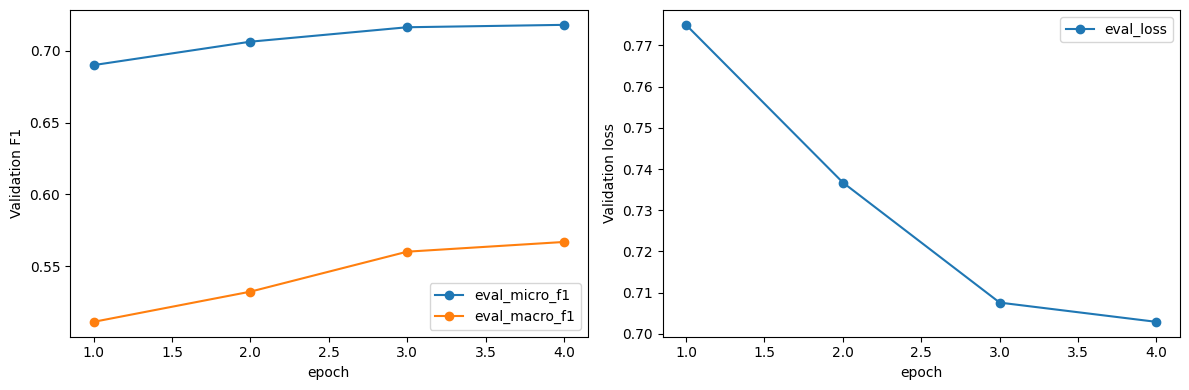

In [10]:
def evaluate_and_save(dataset,frame,prefix):
    output = trainer.predict(dataset,metric_key_prefix=prefix)
    predictions = np.argmax(output.predictions,axis=-1)
    labels = output.label_ids
    assert len(labels)==len(frame), 'Evaluation did not cover all rows.'
    names = [f'{i} star' for i in range(1,6)]
    print(classification_report(labels,predictions,labels=list(range(5)),
                                target_names=names,digits=4,zero_division=0))
    report = classification_report(labels,predictions,labels=list(range(5)),
        target_names=names,output_dict=True,zero_division=0)
    matrix = pd.DataFrame(confusion_matrix(labels,predictions,labels=list(range(5))),
        index=pd.Index(range(1,6),name='Actual'),
        columns=pd.Index(range(1,6),name='Predicted'))
    display(pd.DataFrame([output.metrics]))
    display(matrix)
    (RUN_DIR/f'{prefix}_metrics.json').write_text(json.dumps(output.metrics,indent=2))
    pd.DataFrame(report).T.to_csv(RUN_DIR/f'{prefix}_classification_report.csv')
    matrix.to_csv(RUN_DIR/f'{prefix}_confusion_matrix.csv')
    pd.DataFrame({'source_row_id':frame['source_row_id'].to_numpy(),
                  'actual_rating':labels+1,'predicted_rating':predictions+1
                 }).to_csv(RUN_DIR/f'{prefix}_predictions.csv',index=False)
    return output.metrics

best_validation_metrics = evaluate_and_save(tokenized_datasets['validation'],val_df,'validation')
summary = {
    'run_id':RUN_ID,'model':MODEL_NAME,'split_fingerprint':split_fingerprint,
    'max_length':MAX_LENGTH,'train_batch':TRAIN_BATCH_SIZE,
    'epochs_completed':trainer.state.epoch,
    'input_policy':'conservative_stopwords__original_length_summary_eligibility',
    'remove_stopwords':REMOVE_STOPWORDS,
    'stopword_policy_fingerprint':stopword_policy_fingerprint,
    'preprocessing_seconds':preprocessing_seconds,
    'validation_source_token_reduction_pct':preprocessing_report['validation']['source_token_reduction_pct'],
    'validation_model_input_reduction_pct':preprocessing_report['validation']['model_input_reduction_pct'],
    'effective_train_batch':TRAIN_BATCH_SIZE*GRADIENT_ACCUMULATION_STEPS,
    'peak_gpu_reserved_gb':peak_gpu_reserved_gb,
    'best_epoch':float(epoch_results.loc[epoch_results['eval_micro_f1'].idxmax(),'epoch']),
    'training_wall_seconds':elapsed_seconds,'peak_gpu_memory_gb':peak_gpu_memory_gb,
    **best_validation_metrics,
}
pd.DataFrame([summary]).to_csv(RUN_DIR/'comparison_row.csv',index=False)
display(pd.DataFrame([summary]))

import matplotlib.pyplot as plt
fig,axes = plt.subplots(1,2,figsize=(12,4))
epoch_results.plot(x='epoch',y=['eval_micro_f1','eval_macro_f1'],marker='o',ax=axes[0])
epoch_results.plot(x='epoch',y='eval_loss',marker='o',ax=axes[1])
axes[0].set_ylabel('Validation F1'); axes[1].set_ylabel('Validation loss')
fig.tight_layout()
fig.savefig(RUN_DIR/'validation_curves.png',dpi=150)
plt.show()


## ۸. Test نهایی — اختیاری
هنگام بررسی معماری‌ها خاموش بماند. پس از نهایی‌شدن تصمیم‌ها، RUN_TEST را True کنید و فقط این سلول را اجرا کنید. نتیجه Test برای انتخاب مدل، batch یا epoch استفاده نشود.


In [11]:
if RUN_TEST:
    test_dataset = Dataset.from_pandas(test_df[['reviewText','summary','labels']],preserve_index=False)
    test_dataset = test_dataset.map(tokenize_batch,batched=True,batch_size=256,
                                    remove_columns=['reviewText','summary'],desc='Tokenizing final test')
    final_test_metrics = evaluate_and_save(test_dataset,test_df,'test')
else:
    print('Test evaluation is disabled. Use validation during model development.')


Test evaluation is disabled. Use validation during model development.


## ۹. پیش‌بینی یک متن جدید


In [12]:
def predict_rating(review_text, summary=''):
    if not isinstance(review_text,str) or not review_text.strip():
        raise ValueError('Please provide a non-empty review.')
    summary = '' if summary is None else str(summary)
    encoded = tokenize_batch({'reviewText':[review_text], 'summary':[summary]})
    example = {key:value[0] for key,value in encoded.items()}
    inputs = data_collator([example]).to(trainer.model.device)
    trainer.model.eval()
    with torch.inference_mode():
        probabilities = torch.softmax(trainer.model(**inputs).logits,dim=-1)[0].float().cpu().numpy()
    return {'predicted_rating':int(probabilities.argmax())+1,
            'input_tokens_without_batch_padding':len(example['input_ids']),
            'probabilities':{i+1:round(float(p),4) for i,p in enumerate(probabilities)}}

predict_rating('The headphones sound great and the battery lasts all day.',
               summary='Great headphones')


{'predicted_rating': 5,
 'input_tokens_without_batch_padding': 12,
 'probabilities': {1: 0.0015, 2: 0.0019, 3: 0.0062, 4: 0.055, 5: 0.9354}}

## ۱۰. مقایسه اثر حذف stopword با اجرای قبلی ۲۵۶ توکنی

در `BASELINE_RUN_DIR` پوشه اجرای قبلی ۲۵۶ توکنی را بگذارید. سلول زیر برابری split، summary خام، مدل و تنظیمات آموزش را بررسی می‌کند. Micro/Macro-F1، MAE، loss، تعداد epoch، زمان و حافظه کنار هم نمایش داده می‌شوند. پیش‌بینی‌های دو مدل نیز بر اساس source_row_id به هم متصل و درست/غلط شدن‌ها ذخیره می‌شوند. اختلافی که برچسب‌های واقعی یا عضویت validation آن یکسان نباشد قابل مقایسه نیست و کد آن را رد می‌کند.

**چطور از تصمیم دفاع کنیم؟**

۱. فرضیه و قواعد را با `stopword_policy.json` و مثال‌های واقعی `stopword_examples_train.csv` توضیح دهید. این فهرست از labelها ساخته نشده است. کلمات نفی، شدت، مقایسه، ضمیرها و علائم نگارشی حفظ شده‌اند؛ کاربرد واژه‌ها در انگلیسی بسیار متنوع است و قواعد محافظتی همه حالت‌های معنایی را پوشش نمی‌دهند.

۲. از `preprocessing_report.json` کاهش WordPieceهای متن کامل را جدا از کاهش طول ورودی واقعی مدل گزارش کنید. متن بلند ممکن است پس از حذف هم ۲۵۶ توکن داشته باشد؛ در این حالت صرفه‌جویی اصلی می‌تواند جا دادن اطلاعات بیشتر باشد و کاهش زمان GPU الزاماً رخ نمی‌دهد. زمان پاک‌سازی/توکن‌سازی و زمان آموزش جدا ثبت می‌شوند؛ زمان دانلود مدل و خواندن اولیه داده در این دو زمان نیست.

۳. تغییر Macro-F1 و F1 هر کلاس را کنار Micro-F1 و MAE بررسی کنید. اگر کاهش توکن با افت نامطلوب کیفیت همراه باشد، استفاده از این حذف قابل دفاع نیست. حتی نتیجه منفی آزمایش هم نتیجه علمی قابل گزارش است. برای اختلاف‌های کوچک، هر دو نسخه را با چند seed یکسان تکرار کنید؛ یک اجرا اثبات بهبود پایدار نیست. Test را برای تصمیم نهایی نگه دارید.

۴. هر دو اجرا از یک checkpoint اولیه شروع می‌کنند و همه وزن‌ها fine-tune می‌شوند؛ از بهترین مدل اجرای قبلی ادامه ندهید. معیار انتخاب و حداکثر epoch یکسان‌اند؛ early stopping ممکن است تعداد epoch اجراشده را متفاوت کند. برای نسبت سرعت، GPU و تعداد epoch را نیز مقایسه کنید.

۵. در inference همان `clean_stopwords` و `tokenize_batch` این فایل اعمال شود. `model` و tokenizer ذخیره‌شده به‌تنهایی قواعد حذف و head-tail را اجرا نمی‌کنند. `stopword_policy.json` و `input_preprocessing.json` کنار `best_model` ذخیره می‌شوند.

مراجع: [محدودیت فهرست‌های عمومی stopword در مستندات scikit-learn](https://scikit-learn.org/stable/modules/feature_extraction.html#using-stop-words)، [مقاله BERT و نقش بافت دوطرفه](https://aclanthology.org/N19-1423/)، [Trainer 4.57.1](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer).


In [13]:
if BASELINE_RUN_DIR is not None:
    base_dir=Path(BASELINE_RUN_DIR)
    baseline=pd.read_csv(base_dir/'comparison_row.csv')
    current=pd.read_csv(RUN_DIR/'comparison_row.csv')
    assert len(baseline)==len(current)==1
    assert baseline.iloc[0]['split_fingerprint']==current.iloc[0]['split_fingerprint']
    baseline.insert(0,'experiment','256_without_stopword_removal')
    current.insert(0,'experiment','256_conservative_stopword_removal' if REMOVE_STOPWORDS else '256_control')
    comparison=pd.concat([baseline,current],ignore_index=True)
    columns=['experiment','max_length','train_batch','epochs_completed',
             'validation_micro_f1','validation_macro_f1','validation_accuracy',
             'validation_mae','validation_loss','training_wall_seconds','peak_gpu_memory_gb']
    display(comparison[columns])
    comparison.to_csv(RUN_DIR/'baseline_vs_stopwords.csv',index=False)
    for metric in ['validation_micro_f1','validation_macro_f1','validation_accuracy']:
        change=100*(current.iloc[0][metric]-baseline.iloc[0][metric])
        print(f'{metric} change: {change:+.3f} percentage points')
    for metric in ['validation_mae','validation_loss']:
        change=current.iloc[0][metric]-baseline.iloc[0][metric]
        print(f'{metric} change: {change:+.4f} (negative means improvement)')
    # Per-class reports already use identical 1..5 rating labels.
    old_report=pd.read_csv(base_dir/'validation_classification_report.csv',index_col=0)
    new_report=pd.read_csv(RUN_DIR/'validation_classification_report.csv',index_col=0)
    classes=[f'{i} star' for i in range(1,6)]
    per_class=pd.DataFrame({
        'baseline_f1':old_report.loc[classes,'f1-score'],
        'stopword_f1':new_report.loc[classes,'f1-score'],
        'support':new_report.loc[classes,'support']})
    per_class['delta_f1_percentage_points']=100*(per_class['stopword_f1']-per_class['baseline_f1'])
    display(per_class)
    per_class.to_csv(RUN_DIR/'per_class_f1_comparison.csv')
    old_predictions=pd.read_csv(base_dir/'validation_predictions.csv')
    new_predictions=pd.read_csv(RUN_DIR/'validation_predictions.csv')
    paired=old_predictions.merge(new_predictions,on='source_row_id',how='outer',
                                 suffixes=('_baseline','_stopwords'),validate='one_to_one',indicator=True)
    assert paired['_merge'].eq('both').all(), 'Validation membership changed.'
    assert paired['actual_rating_baseline'].eq(paired['actual_rating_stopwords']).all()
    old_correct=paired['actual_rating_baseline'].eq(paired['predicted_rating_baseline'])
    new_correct=paired['actual_rating_stopwords'].eq(paired['predicted_rating_stopwords'])
    print('Previously wrong, now correct:',int((~old_correct & new_correct).sum()))
    print('Previously correct, now wrong:',int((old_correct & ~new_correct).sum()))
    paired.drop(columns=['_merge']).to_csv(RUN_DIR/'paired_validation_predictions.csv',index=False)
    print('Validation token changes:',preprocessing_report['validation'])
    if baseline_config['gpu'] != torch.cuda.get_device_name(0):
        print('GPU differs from baseline; training times have different hardware conditions.')
else:
    print('For the controlled comparison, set BASELINE_RUN_DIR to the previous 256-token run.')


For the controlled comparison, set BASELINE_RUN_DIR to the previous 256-token run.


این فایل نتیجه آموزشی از پیش محاسبه‌شده ندارد. عددهای واقعی پس از اجرای داده روی GPU ثبت می‌شوند.
